# Lab Exp 2: Shape Recovery using DFD and Photometric Stereo

Install once: `pip install numpy opencv-python matplotlib`

In [14]:
pip install numpy opencv-python matplotlib

In [15]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'dfd_relative_depth.png', 'light2.jpg', 'light3.jpg', 'photometric_depth.png', 'focus_far.jpg', 'photometric_albedo.png', 'focus_near.jpg', 'light4.jpg', 'light1.jpg', 'sample_data']


Created six new images:
focus_near.jpg, focus_far.jpg, light1.jpg, light2.jpg, light3.jpg, light4.jpg


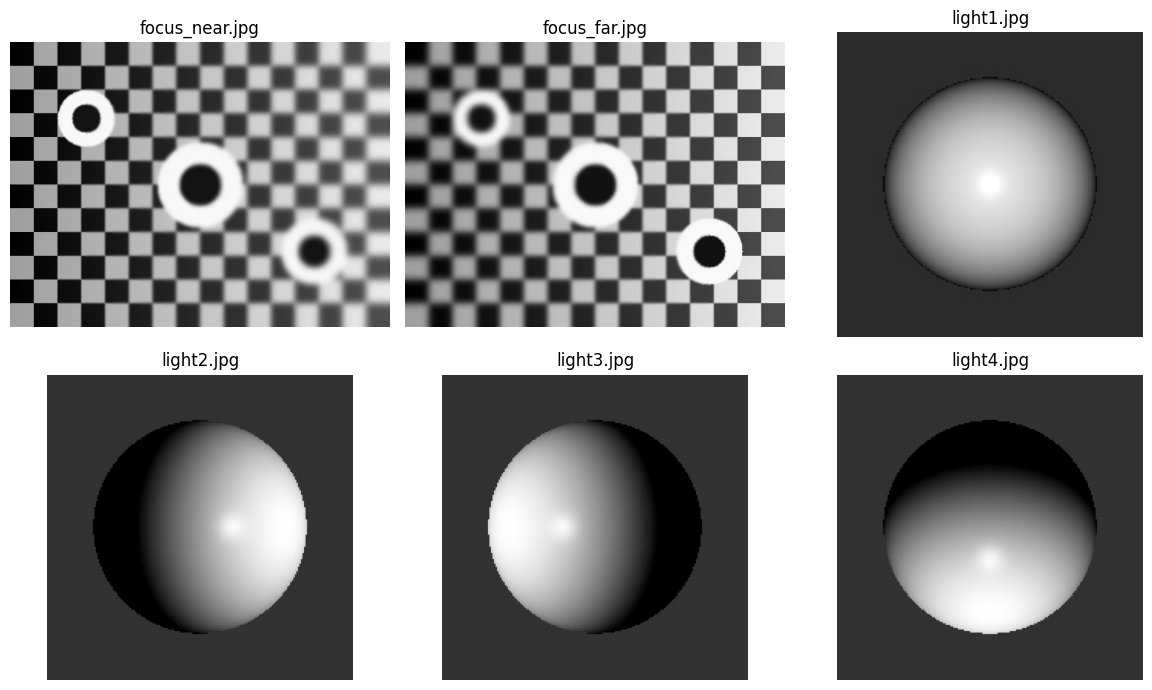

In [16]:
# ---- Run this cell ONCE before Part A: creates 6 different sample images ----

import cv2
import numpy as np

# ==========================================================
# 1. DEPTH FROM DEFOCUS (DFD): Checkerboard with depth gradient
# ==========================================================

h, w = 300, 400
y, x = np.mgrid[0:h, 0:w]

# Create a colorful-looking grayscale geometric scene
checker = ((x // 25 + y // 25) % 2).astype(np.float32)
gradient = np.tile(np.linspace(0.2, 0.8, w), (h, 1))

# Combine checkerboard and smooth intensity gradient
scene = 0.55 * checker + 0.45 * gradient

# Add circles and lines for more visual detail
for cx, cy, radius in [(80, 80, 30), (200, 150, 45), (320, 220, 35)]:
    cv2.circle(scene, (cx, cy), radius, 0.95, -1)
    cv2.circle(scene, (cx, cy), radius // 2, 0.15, -1)

scene = np.clip(scene, 0, 1)

# Depth increases from left to right
depth = np.tile(np.linspace(0, 1, w), (h, 1))

# Create two images with opposite focus directions
focus_near = np.zeros_like(scene)
focus_far = np.zeros_like(scene)

for row in range(h):
    for col in range(w):
        sigma_near = 0.1 + depth[row, col] * 4
        sigma_far = 0.1 + (1 - depth[row, col]) * 4

        # Use pre-blurred images for efficient depth-dependent blur
        pass

blur_levels = np.linspace(0.1, 4.0, 15)
blur_stack = np.stack([
    cv2.GaussianBlur(scene, (0, 0), float(s))
    for s in blur_levels
])

def apply_depth_blur(depth_map):
    indices = np.abs(
        depth_map[..., None] * 4 - blur_levels
    ).argmin(axis=2)
    return blur_stack[indices, np.arange(h)[:, None], np.arange(w)]

focus_near = apply_depth_blur(depth)
focus_far = apply_depth_blur(1 - depth)

cv2.imwrite("focus_near.jpg", (focus_near * 255).astype(np.uint8))
cv2.imwrite("focus_far.jpg", (focus_far * 255).astype(np.uint8))


# ==========================================================
# 2. PHOTOMETRIC STEREO: 3D SPHERE WITH FOUR LIGHT DIRECTIONS
# ==========================================================

n = 200
yy, xx = np.mgrid[-1:1:complex(n), -1:1:complex(n)]

radius = 0.7
r2 = xx**2 + yy**2
inside = r2 <= radius**2

# Surface normals of a sphere
zz = np.sqrt(np.maximum(0, radius**2 - r2))
normals = np.stack([xx, yy, zz], axis=2)
normals /= np.maximum(
    np.linalg.norm(normals, axis=2, keepdims=True), 1e-8
)

# Sphere has a lighter surface, background is darker
albedo = np.where(inside, 0.9, 0.25)

# Four different lighting directions
lights = np.array([
    [0, 0, 1],
    [0.8, 0, 0.6],
    [-0.8, 0, 0.6],
    [0, 0.8, 0.6]
], dtype=float)

lights /= np.linalg.norm(lights, axis=1, keepdims=True)

for i, light in enumerate(lights):
    diffuse = np.maximum(
        0, np.sum(normals * light, axis=2)
    )

    image = np.where(inside, albedo * diffuse, 0.18)

    # Add a small specular highlight
    highlight = np.exp(
        -((xx - light[0] * 0.25)**2 +
          (yy - light[1] * 0.25)**2) / 0.008
    )

    image = np.clip(image + 0.15 * highlight * inside, 0, 1)

    cv2.imwrite(
        f"light{i+1}.jpg",
        (image * 255).astype(np.uint8)
    )


# ==========================================================
# 3. DISPLAY ALL SIX GENERATED IMAGES
# ==========================================================

print("Created six new images:")
print("focus_near.jpg, focus_far.jpg, light1.jpg, light2.jpg, light3.jpg, light4.jpg")

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

filenames = [
    "focus_near.jpg", "focus_far.jpg",
    "light1.jpg", "light2.jpg", "light3.jpg", "light4.jpg"
]

for ax, filename in zip(axes.ravel(), filenames):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Implementation A — Depth from Defocus (DFD)
Inputs: `focus_near.jpg`, `focus_far.jpg`

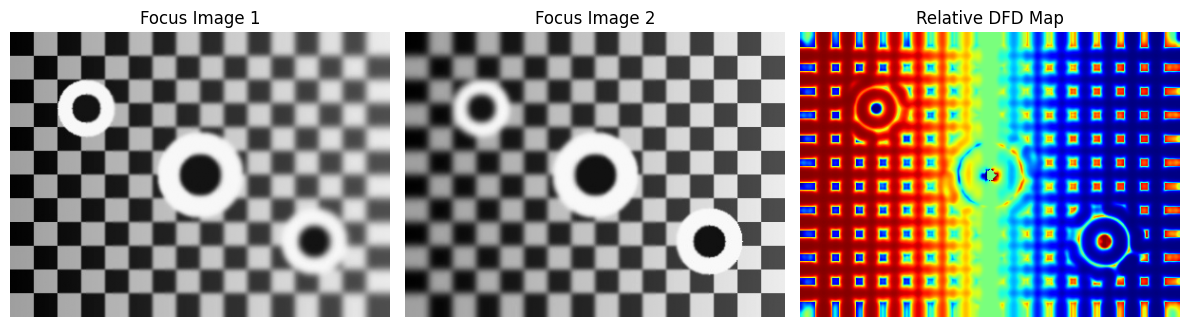

True

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the two images captured at different focus settings
img1 = cv2.imread("focus_near.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.jpg", cv2.IMREAD_GRAYSCALE)

# 2. Check that both images were loaded
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image names and file paths.")

# 3. Make both images the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 4. Apply a small Gaussian blur to reduce sensor noise
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

# 5. Calculate the Laplacian response
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 6. Estimate local focus using squared Laplacian
kernel = (15, 15)
focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

# 7. Compare the focus measures
eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)

# 8. Convert the relative focus difference into a displayable map
depth_map = cv2.normalize(focus_diff, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 9. Display the input images and the DFD result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Focus Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Focus Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(depth_map, cmap="jet")
plt.title("Relative DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Save the result
cv2.imwrite("dfd_relative_depth.png", depth_map)


## Implementation B — Photometric Stereo
Inputs: `light1.jpg` … `light4.jpg` (replace `L` with your real light directions)

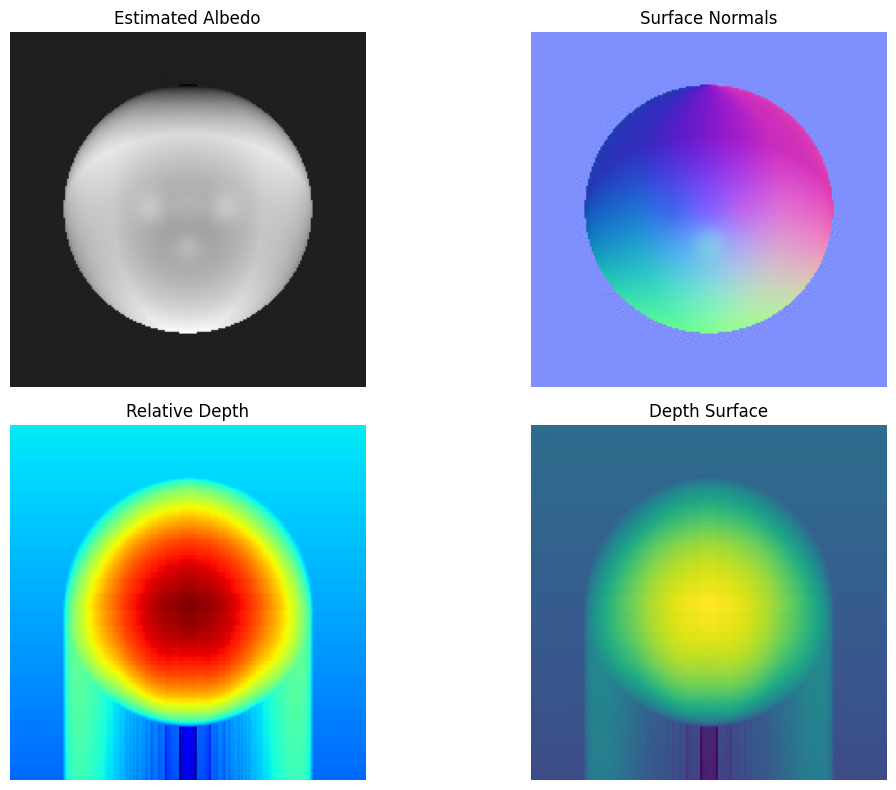

True

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read four grayscale images of the same object
files = ["light1.jpg", "light2.jpg", "light3.jpg", "light4.jpg"]
images = []

for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")
    images.append(img.astype(np.float64) / 255.0)

# 2. Stack the images: shape = (number_of_images, height, width)
I = np.stack(images, axis=0)

# 3. Known light directions [lx, ly, lz]
# Replace these with the directions used during your own capture.
L = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)

# 4. Normalize every light direction
L = L / np.linalg.norm(L, axis=1, keepdims=True)

# 5. Compute the pseudo-inverse of the lighting matrix
L_pinv = np.linalg.pinv(L)

# 6. Rearrange image data so each pixel has an intensity vector
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 7. Estimate scaled surface normals g = L+ I
G = L_pinv @ I_pixels

# 8. Calculate albedo = magnitude of the scaled normal
albedo = np.linalg.norm(G, axis=0)

# 9. Normalize G to obtain unit surface normals
normals = G / (albedo[None, :] + 1e-8)

# 10. Extract normal components
nx = normals[0].reshape(h, w)
ny = normals[1].reshape(h, w)
nz = normals[2].reshape(h, w)

# 11. Convert normals to surface gradients
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# 12. Simple path integration to obtain a relative depth map
depth = np.zeros((h, w), dtype=np.float64)

# Integrate p along x direction
for y in range(h):
    depth[y, 1:] = np.cumsum(p[y, :-1])

# Add q contribution along y direction
for x in range(w):
    depth[1:, x] += np.cumsum(q[:-1, x])

# 13. Normalize depth only for visualization
depth_vis = cv2.normalize(depth, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 14. Normalize albedo for visualization
albedo_vis = cv2.normalize(albedo.reshape(h, w), None, 0, 255,
                           cv2.NORM_MINMAX).astype(np.uint8)

# 15. Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(albedo_vis, cmap="gray")
plt.title("Estimated Albedo")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(np.dstack([
    (nx + 1) / 2,
    (ny + 1) / 2,
    (nz + 1) / 2
]))
plt.title("Surface Normals")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(depth_vis, cmap="jet")
plt.title("Relative Depth")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(depth, cmap="viridis")
plt.title("Depth Surface")
plt.axis("off")

plt.tight_layout()
plt.show()

# 16. Save outputs
cv2.imwrite("photometric_albedo.png", albedo_vis)
cv2.imwrite("photometric_depth.png", depth_vis)
